In [1]:
import numpy as np #Numpy, various array and statistics functions for handling data
import math #shortcuts for some math symbols, operations in python
import matplotlib.pyplot as plt #Allows plotting the images and displaying
import astropy.units as u #Easy shortcut for attaching units to numbers
from astropy.io import fits #Allows handling of fits files input/output
from photutils.psf import fit_fwhm #Used to fit a gaussian onto stars and measure fwhm
from photutils.profiles import RadialProfile #Used to find the radial profile of the globular cluster and find the half light radius

#from characterize_CCD lab
import os #Functions to interact with the computer system like files
from astropy.wcs import WCS #Allows world coordinate system functions
from astropy.nddata import CCDData #Allows storage of an image including its units
from scipy.stats import scoreatpercentile #How the pixel values are cut to display an image useful to human eyes
import glob #Pattern-matching syntax, we used it in reduction lab for picking out the right fits to combine by their file names.
%matplotlib inline
#The above is a jupyter notebook thing which makes the plots appear right below the cells that call to display
from ccdproc import ImageFileCollection, Combiner, combine #Tools for stacking raw frames might not be needed since our data is already processed
from ccdproc import wcs_project #Reprojects images using WCS onto new coordinate grids when combining dithered images

#from cluster photometry lab
from photutils.detection import DAOStarFinder #Finds stars in an image
from astropy.stats import sigma_clipped_stats #Allows clipping out of stuff by their sigma value and gives stats on data
from photutils.aperture import CircularAperture #Place circular apertures on stars
from astropy.visualization import SqrtStretch #Square-root stretch so faint and bright stars both show, adapt image for human viewing
from astropy.visualization.mpl_normalize import ImageNormalize #Applies a stretch when displaying an image
from astropy.coordinates import SkyCoord #Stores positions in sky and matches the positions to stars in catalogs

# Analysis of M5 (Globular Cluster)

### Importing and Displaying Data for M5

In [193]:
# RA =  15:18:33.22
# Dec = +02:04:51.7

'''
data1, header1 = fits.getdata("cutout_229.6383_2.0808.fits", header=True)
data2, header2 = fits.getdata("cutout_229.6362_2.0609.fits", header=True)
data3, header3 = fits.getdata("cutout_229.6420_2.0902.fits", header=True)
'''

# cutout_229.6420_2.0902.fits has more of the cluster in frame
M5_data, M5_header = fits.getdata("cutout_229.6420_2.0902.fits", header=True)

In [194]:
print(M5_header)

SIMPLE  =                    T / file does conform to FITS standard             BITPIX  =                  -32 / number of bits per data pixel                  NAXIS   =                    3 / number of data axes                            NAXIS1  =                  256 / length of data axis 1                          NAXIS2  =                  256 / length of data axis 2                          NAXIS3  =                    3 / length of data axis 3                          EXTEND  =                    T / FITS dataset may contain extensions            COMMENT   FITS (Flexible Image Transport System) format is defined in 'AstronomyCOMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H SURVEY  = 'LegacySurvey'                                                        VERSION = 'DR11    '                                                            IMAGETYP= 'IMAGE   '           / None                                           BANDS   = 'grz     '                    

In [195]:
#print(header1)

In [196]:
#print(header2)

In [197]:
#print(header3)

In [198]:
'''
# Data has a third axis. I believe that is each band. Bands listed are g, r, and z for 0, 1, and 2, respectively.
M5_data_g = M5_data[0]
M5_data_r = M5_data[1]
M5_data_z = M5_data[2]
'''

'\n# Data has a third axis. I believe that is each band. Bands listed are g, r, and z for 0, 1, and 2, respectively.\nM5_data_g = M5_data[0]\nM5_data_r = M5_data[1]\nM5_data_z = M5_data[2]\n'

In [199]:
# Data has a third axis. I believe that is each band. Bands listed are g, r, and z for 0, 1, and 2, respectively.
M5_data_list = []

M5_band_list = ["g","r"]
for i in M5_data:
    M5_data_list.append(i)

In [200]:
def imdisplay(image, v1perc=10, v2perc=95, logscale=True):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    fig,ax = plt.subplots(figsize=(6,6))
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    print(v1,v2)
    if (logscale):
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
    else:
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')
        
    cbar = fig.colorbar(im, ax=ax, fraction=0.04)
    cbar.ax.set_ylabel('counts')
    return fig,ax

-0.0012777181982528418 10.8770707082749
-0.0017138301453087478 15.44058883667001


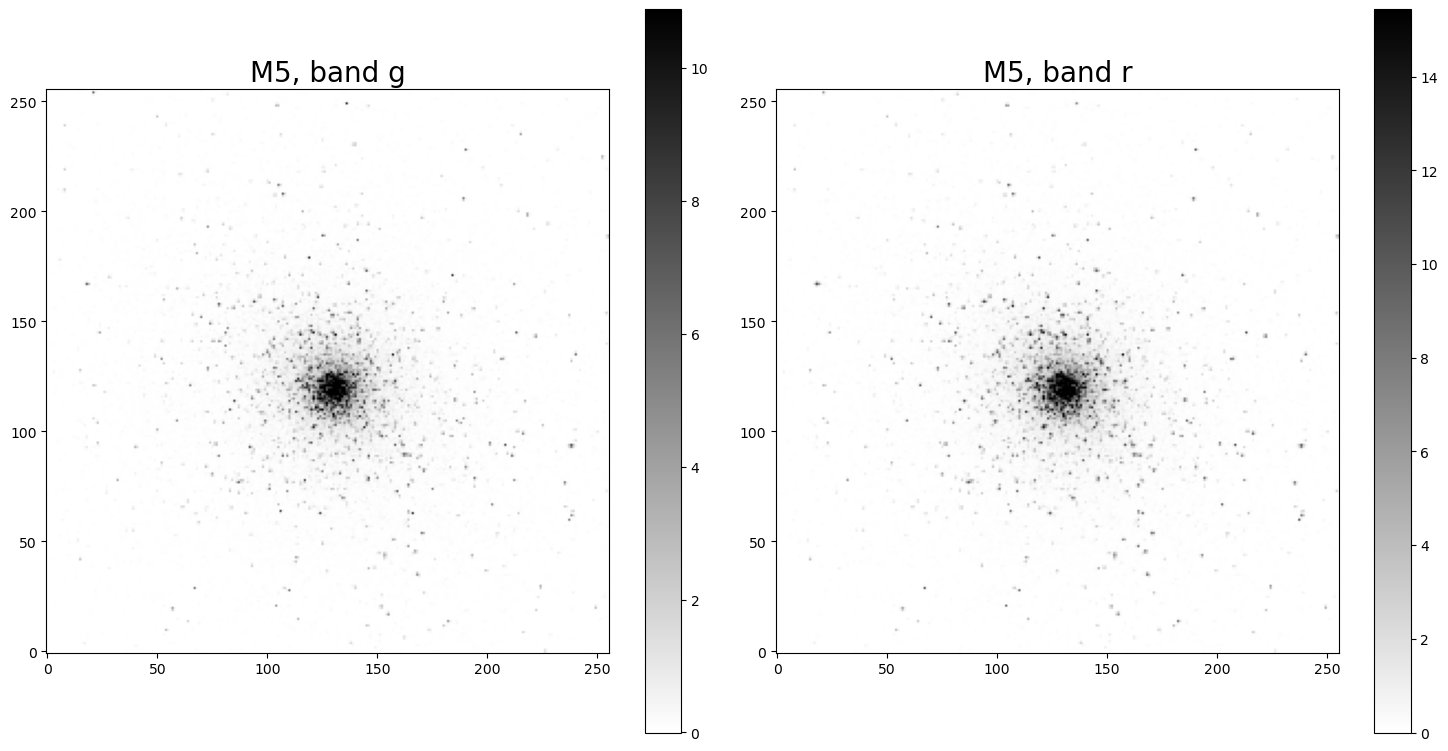

In [201]:
fig1 = plt.figure(1, figsize=(15,15))

for i in range(len(M5_band_list)):
    ax = plt.subplot(2,2,i+1)
    nimage = np.array(M5_data_list[i])
    # Determine the pixel values at the 1st and 99.9th percentile (basically all of them). These will be the min and max of the colormap.
    v1 = scoreatpercentile(nimage, 1.0)
    v2 = scoreatpercentile(nimage, 99.9)
    print(v1, v2)
    plt.imshow(M5_data_list[i], cmap="gray_r", origin="lower", vmin=v1, vmax=v2)
    plt.title(f"M5, band {M5_band_list[i]}", fontsize=20)
    plt.colorbar()
plt.tight_layout()

# Photometry of M5

All images already have matching WCS.

To find the outer stars, first find the center of the cluster, then create increasingly large circles centered on that center and calculate the flux from within it to determine the cluster's profile.
From there, we can determine which radiative profile represents the outer stars.

### Removing Background
The corners can be used as an approximation of background. By subtracting that from the pixels in the image, we can remove the background.

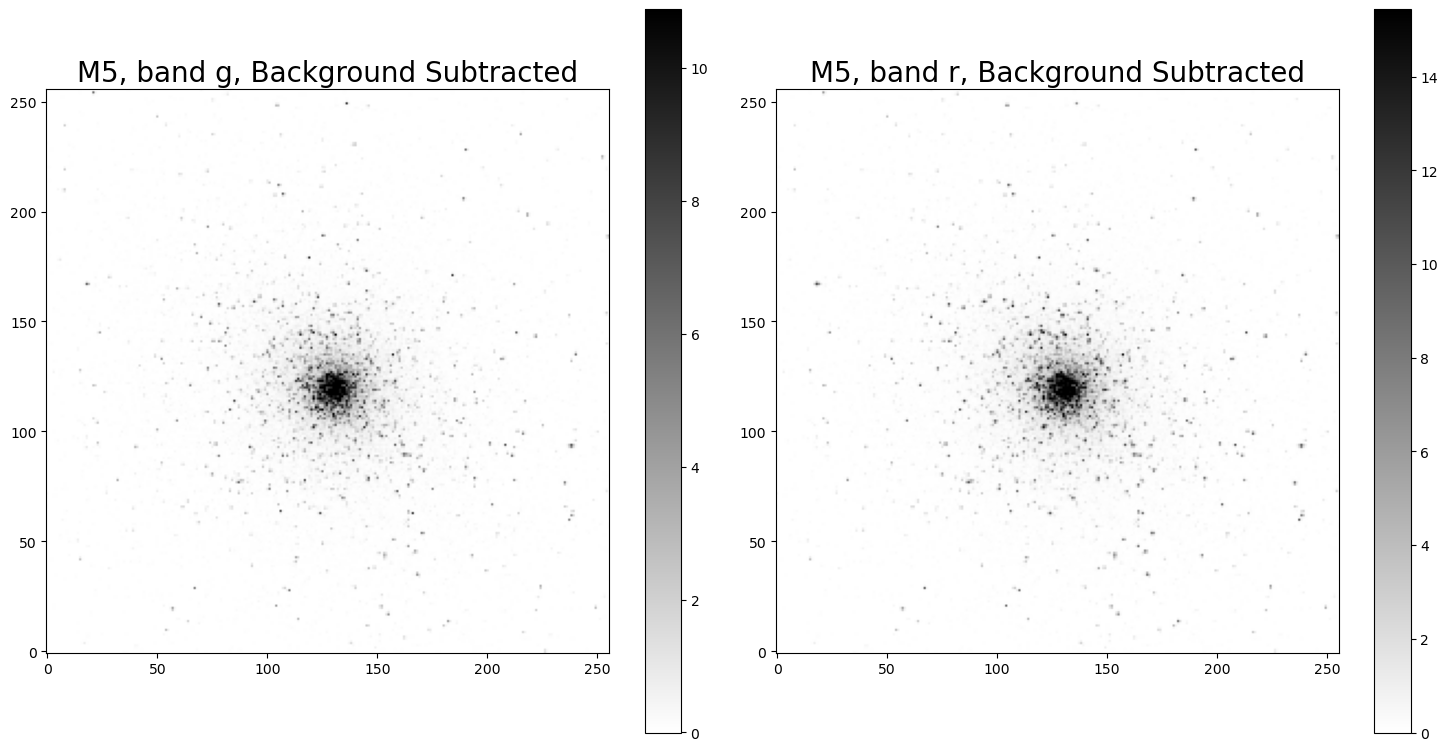

In [202]:
# Plotting the images with the squares for background subtraction
# Corner squares should be 40x40
M5_data_list_bsub = []
fig2 = plt.figure(1, figsize=(15,15))

for i in range(len(M5_band_list)):
    # Squares should be 40x40
    M5_data_bkg = M5_data_list[i]
    UpperLeftSquare = M5_data_bkg[:40, :40]
    LowerRightSquare = M5_data_bkg[-40:, -40:]
    UpperRightSquare = M5_data_bkg[:40, -40:]
    LowerLeftSquare = M5_data_bkg[-40:, :40]
    M5_bkg = []
    M5_bkg.append(UpperLeftSquare)
    M5_bkg.append(LowerRightSquare)
    M5_bkg.append(UpperRightSquare)
    M5_bkg.append(LowerLeftSquare)
    # Find the median of the values in the background squares
    M5_bkg_med = np.median(M5_bkg)
    # Subtract that median from each of the pixels in the images
    M5_data_bsub = M5_data_bkg - M5_bkg_med
    M5_data_list_bsub.append(M5_data_bsub)
    
    nimage_bsub = np.array(M5_data_bsub)
    # Determine the pixel values at the 1st and 99.9th percentile (basically all of them). These will be the min and max of the colormap.
    v1 = scoreatpercentile(nimage_bsub, 1.0)
    v2 = scoreatpercentile(nimage_bsub, 99.9)
    
    ax = plt.subplot(2,2,i+1)
    plt.imshow(M5_data_bsub, cmap="gray_r", origin="lower", vmin=v1, vmax=v2)
    plt.title(f"M5, band {M5_band_list[i]}, Background Subtracted", fontsize=20)
    plt.colorbar()
plt.tight_layout()

### Finding The Outer Stars

Find halflight radius

Text(0.5, 0, 'Radius')

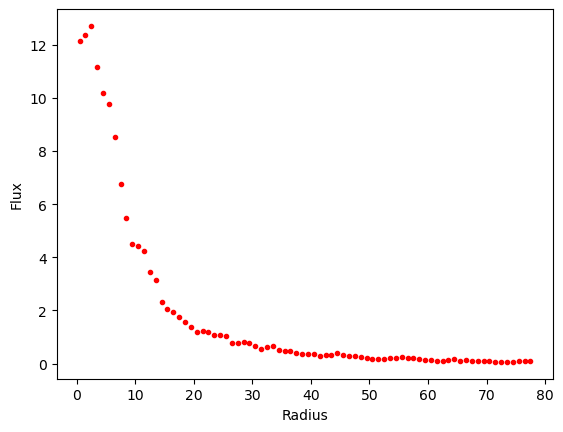

In [203]:
# Initial guesses of center and SemiMajor axis in pixels; SemiMajor axis = SemiMinor axis for the shape chosen
# [129.8370pix, 119.3202pix], [22.0710pix, 20.3900pix]
M5_xcen = 129.1643
M5_ycen = 118.9031
M5_smaj = 78.2194
# Same for all bands

M5_data_g_bsub = M5_data_list_bsub[0]
M5_data_r_bsub = M5_data_list_bsub[1]

rp = RadialProfile(data=M5_data_g_bsub, xycen=(M5_xcen, M5_ycen), radii=np.arange(0,78.2194))
plt.errorbar(rp.radius, rp.profile, fmt='r.')
plt.ylabel("Flux")
plt.xlabel("Radius")


In [204]:
print(rp.profile[5])
print(rp.radius[5])

9.770441065377028
5.5


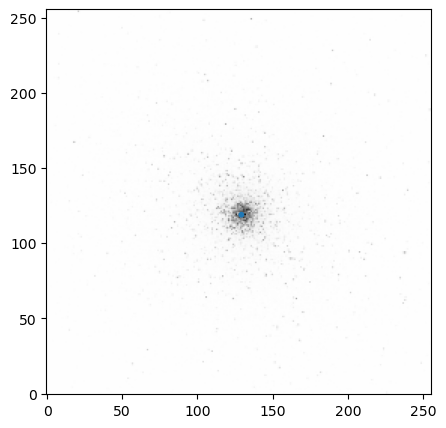

In [205]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(M5_data_g_bsub, origin='lower', cmap='Grays')
for i in range(1):
    rp.apertures[i].plot(ax=ax, color=f'C{i}', lw=2)

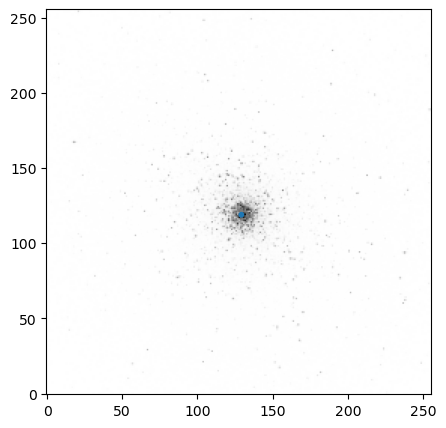

In [206]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(M5_data_r_bsub, origin='lower', cmap='Grays')
for i in range(1):
    rp.apertures[i].plot(ax=ax, color=f'C{i}', lw=2)

### Masking the stars inside the center

In [207]:
# Masking Pixels falling within the half light radius
half_light_radius = rp.radius[0] # Pixels; can be varried to include more of the cluster

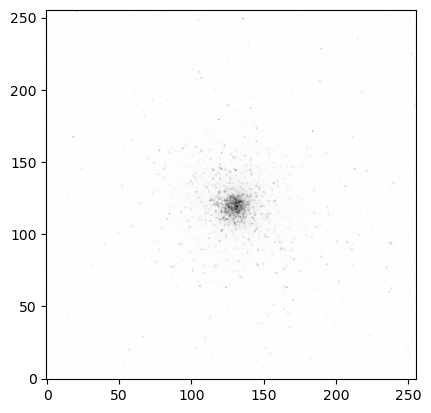

In [208]:


# Loop checks if a given pixel is within the half light radius and adds them to an array if they are.
M5_data_g_bsub_masked = M5_data_list_bsub[0]
for i in np.arange(0,M5_header["NAXIS1"]):
    for j in np.arange(0,M5_header["NAXIS2"]):
        r = math.sqrt(((i-M5_xcen)**2)+((j-M5_ycen)**2))    # radial distance from center calculation
        if r <= half_light_radius:
            M5_data_g_bsub_masked[j][i] = np.nan
plt.imshow(M5_data_g_bsub_masked, cmap='Grays', origin="lower")

#Save the image as a new fits file
fits.writeto('M5G.fits', M5_data_g_bsub_masked, overwrite=True, header=M5_header)

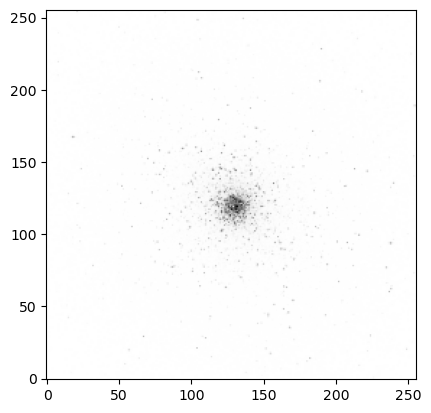

In [209]:
# Same thing for the r band
M5_data_r_bsub_masked = M5_data_list_bsub[1]
for i in np.arange(0,M5_header["NAXIS1"]):
    for j in np.arange(0,M5_header["NAXIS2"]):
        r = math.sqrt(((i-M5_xcen)**2)+((j-M5_ycen)**2))    # radial distance from center calculation
        if r <= half_light_radius:
            M5_data_r_bsub_masked[j][i] = np.nan
plt.imshow(M5_data_r_bsub_masked, cmap='Grays', origin="lower")

#Save the image as a new fits file
fits.writeto('M5R.fits', M5_data_r_bsub_masked, overwrite=True, header=M5_header)

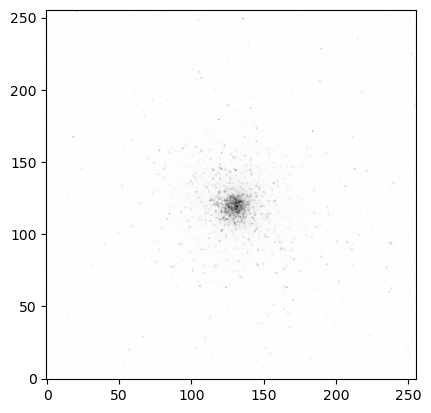

In [210]:
# Testing the new fits files
plt.imshow(fits.getdata('M5G.fits'), cmap='Grays', origin="lower")

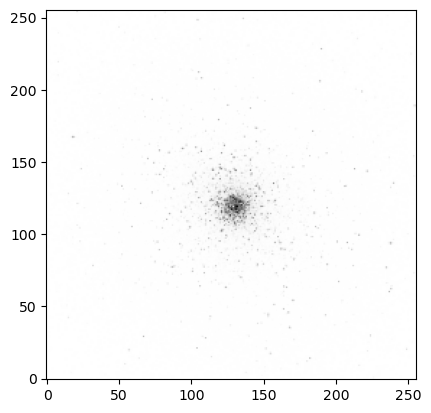

In [211]:
plt.imshow(fits.getdata('M5R.fits'), cmap='Grays', origin="lower")

## PSF Measurement
Fits FWHM to the outer stars of the cluster 

### Sigma Clipping

In [212]:
# Sigma Clip each image to further remove background

# Obtain mean, median, std dev
for i in range(len(M5_band_list)):
    M5_mean, M5_median, M5_stdev = sigma_clipped_stats(M5_data_list[i], sigma=3.0)
    print(f"{M5_band_list[i]} Mean", M5_mean)
    print(f"{M5_band_list[i]} Median", M5_median)
    print(f"{M5_band_list[i]} Std Dev", M5_stdev)

g Mean 0.01772707
g Median 0.005419096
g Std Dev 0.026131192
r Mean 0.028951237
r Median 0.010552436
r Std Dev 0.040230278


In [213]:
# PSF measurement function from lab
from astropy.io import fits
from photutils.psf import fit_fwhm

def calc_fwhm(imagefilename, xyposlist):
    '''
    This function takes as input an image file name and a list of star pixel coordinates 
    and prints the FWHM for each star.  

    Stars should be bright, unsaturated, and isolated.

    INPUTS: 
    imagefilename: a string containing the image file name

    xyposlist: a list of x and y coordinates of the form [(x1,y1), (x2,y2)]
    This can contain an arbitrary number of stars.

    OUTPUT:
    fwhmlist: a list of FWHM
    '''
    image = fits.getdata(imagefilename)
    
    #use the photutils.psf.fit_fwhm function to fit a 2D PSF to the stars.
    fwhm = fit_fwhm(
        image,
        xypos=xyposlist,
        fwhm=4.0,        # initial guess from lab
        fit_shape=21
    )
    print(f'The FWHM of the stars in {imagefilename} in pixels are {fwhm}')
    return(fwhm)

In [214]:
# 5 stars in M5 in pixel coordinates
M5_stars = [(184.0285, 170.9012), (119.0643, 178.9181), (116.9973, 77.7644), (106.0191, 63.8749), (124.0330, 62.8438)]

In [215]:
# FWHM of each of the stars
M5_fwhmlist_g = calc_fwhm('M5G.fits', M5_stars)
M5_fwhmlist_r = calc_fwhm('M5R.fits', M5_stars)

# Average FWHM
M5_fwhm_g = np.mean(M5_fwhmlist_g)
M5_fwhm_r = np.mean(M5_fwhmlist_r)

The FWHM of the stars in M5G.fits in pixels are [0.5143377  0.68096822 0.57113918 0.36625711 0.77786807]
The FWHM of the stars in M5R.fits in pixels are [0.77869986 0.78182155 0.85723971 0.72655506 1.07312389]


In [216]:
M5_data_g, M5_header_g = fits.getdata('M5G.fits', header=True)
M5_data_r, M5_header_r = fits.getdata('M5R.fits', header=True)

In [217]:
# Obtain mean, median, std dev
M5_mean_g, M5_median_g, M5_stdev_g = sigma_clipped_stats(M5_data_g, sigma=3.0)
M5_mean_r, M5_median_r, M5_stdev_r = sigma_clipped_stats(M5_data_r, sigma=3.0)

Text(0.5, 1.0, 'g-band detected sources')

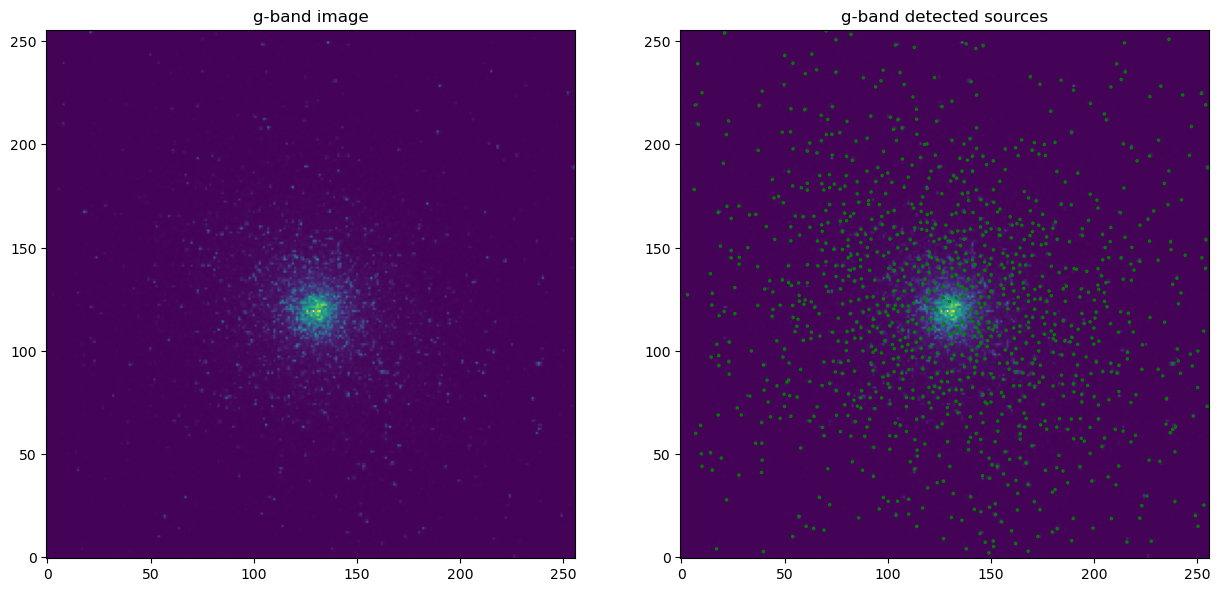

In [218]:
# set up daofind, with info about our image fwhm and the detection threshold
#*****************************************
daofind = DAOStarFinder(fwhm=M5_fwhm_g, threshold=6.0*M5_stdev_g) #was 4, switched to 10.0 to optimize detection from graph of next code cell.

# detect sources, using the image - median, which subtracts the sky level from the image, 
# assuming a sky that is constant across the image
sources_g = daofind(M5_data_g - M5_median_g)

M5_wcs_g = WCS(M5_header_g)
M5_ra_g,M5_dec_g = M5_wcs_g.wcs_pix2world(sources_g['xcentroid'],sources_g['ycentroid'],0)

# plot images and the sources.  using the subplot command we can plot figures side by side
plt.figure(figsize=(15,10))
# select the left plot
plt.subplot(1,2,1)
plt.imshow(M5_data_g, origin='lower')
plt.title('g-band image')

# plot r-band image with the positions of the sources overlaid
# select the right plot
plt.subplot(1,2,2)

# Create a list of positions of all the stars, as determined by the DAOStarFinder above.  
# The transpose command puts the positions into the correct format
positions = np.transpose((sources_g['xcentroid'], sources_g['ycentroid']))
# creates a set of circular apertures (r=1 chosen since stars are small and image is dense)
apertures = CircularAperture(positions, r=0.5)
plt.imshow(M5_data_g, origin='lower')
# plot the apertures. the ';' at the end suppresses some messy output
apertures.plot(color='green', lw=1.0, alpha=1.0);
plt.title('g-band detected sources')

Text(0.5, 1.0, 'g-band')

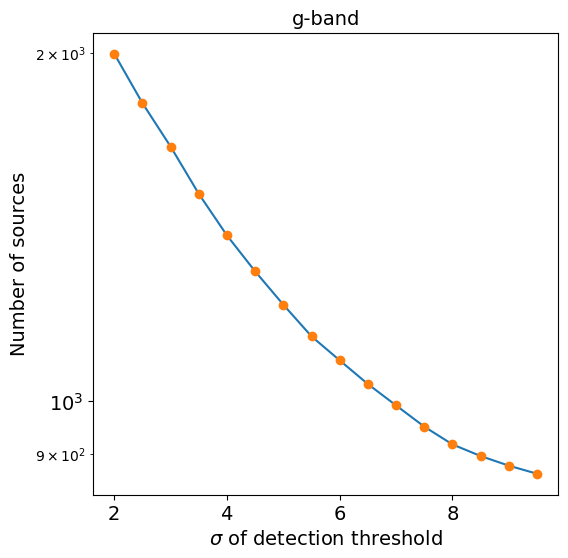

In [219]:
# This makes a plot of the number of sources for different detection thresholds for the g-band
# set up an array of thresholds
thresharr = np.arange(2.,10.,0.5)

# initialize an array that will hold the number of sources detected at each threshold
nsources_g = np.zeros(len(thresharr))

# loop through the thresholds to find how many sources are detected at each threshold
for ithresh,thresh in enumerate(thresharr):
    daofind_tmp = DAOStarFinder(fwhm=M5_fwhm_g, threshold=thresh*M5_stdev_g)
    sources_gtmp = daofind_tmp(M5_data_g - M5_median_g)
    nsources_g[ithresh] = len(sources_gtmp)

# plot the number of sources at each threshold
fig,ax = plt.subplots(figsize=(6,6))
ax.plot(thresharr,nsources_g)
ax.plot(thresharr,nsources_g, 'o')
ax.set_yscale('log')
ax.set_ylabel('Number of sources', fontsize=14)
ax.set_xlabel(r'$\sigma$ of detection threshold', fontsize=14)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
ax.set_title('g-band', fontsize=14)

Text(0.5, 1.0, 'r-band detected sources')

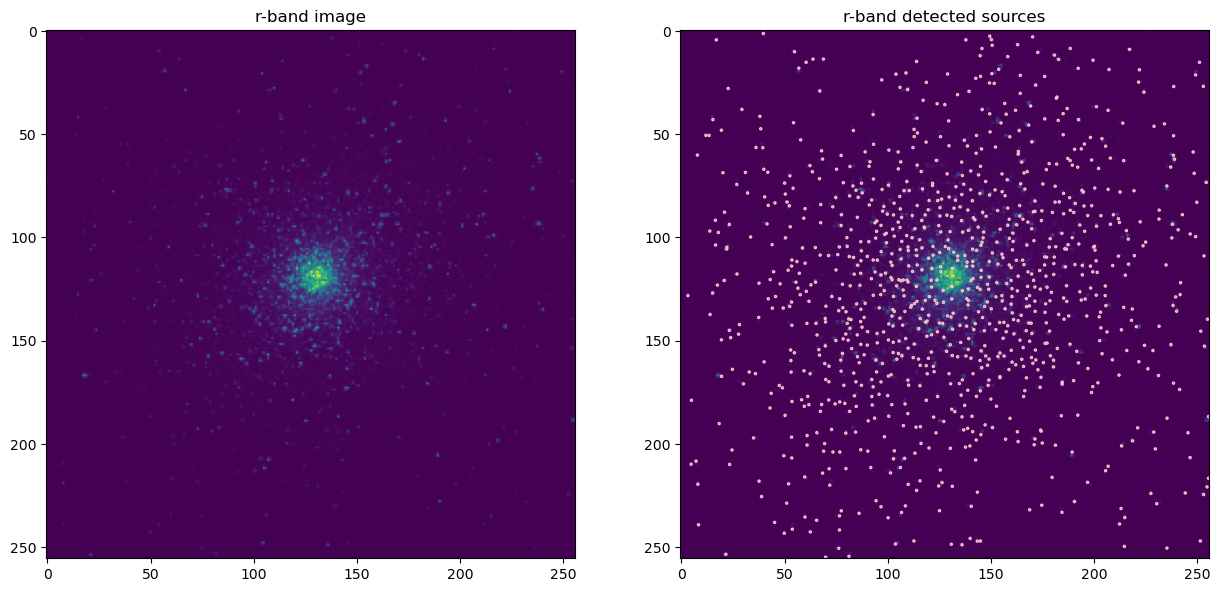

In [220]:
# set up daofind, with info about our image fwhm and the detection threshold
#*****************************************
daofind = DAOStarFinder(fwhm=M5_fwhm_r, threshold=6.0*M5_stdev_r) #was 4, switched to 10.0 to optimize detection from graph of next code cell.

# detect sources, using the image - median, which subtracts the sky level from the image, 
# assuming a sky that is constant across the image
sources_r = daofind(M5_data_r - M5_median_r)

M5_wcs_r = WCS(M5_header_r)
M5_ra_r,M5_dec_r = M5_wcs_r.wcs_pix2world(sources_r['xcentroid'],sources_r['ycentroid'],0)

# plot images and the sources.  using the subplot command we can plot figures side by side
plt.figure(figsize=(15,10))
# select the left plot
plt.subplot(1,2,1)
plt.imshow(M5_data_r)
plt.title('r-band image')

# plot r-band image with the positions of the sources overlaid
# select the right plot
plt.subplot(1,2,2)

# Create a list of positions of all the stars, as determined by the DAOStarFinder above.  
# The transpose command puts the positions into the correct format
positions = np.transpose((sources_r['xcentroid'], sources_r['ycentroid']))
# creates a set of circular apertures (r=1 chosen since stars are small and image is dense)
apertures = CircularAperture(positions, r=0.5)
plt.imshow(M5_data_r)
# plot the apertures. the ';' at the end suppresses some messy output
apertures.plot(color='pink', lw=1.0, alpha=1.0);
plt.title('r-band detected sources')

Text(0.5, 1.0, 'r-band')

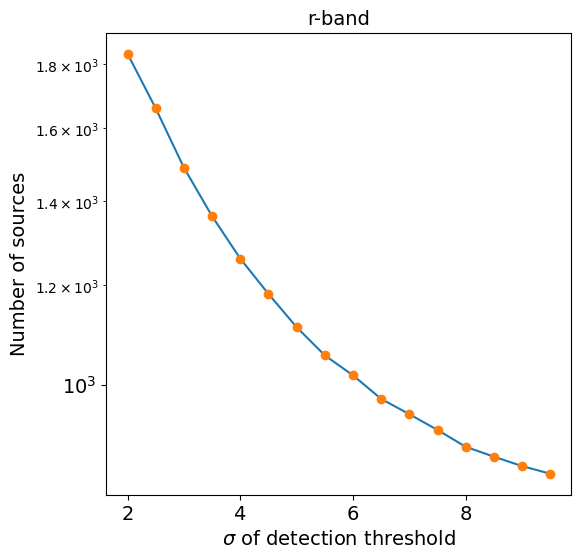

In [221]:
# This makes a plot of the number of sources for different detection thresholds for the r-band
# set up an array of thresholds
thresharr = np.arange(2.,10.,0.5)

# initialize an array that will hold the number of sources detected at each threshold
nsources_r = np.zeros(len(thresharr))

# loop through the thresholds to find how many sources are detected at each threshold
for ithresh,thresh in enumerate(thresharr):
    daofind_tmp = DAOStarFinder(fwhm=M5_fwhm_r, threshold=thresh*M5_stdev_r)
    sources_rtmp = daofind_tmp(M5_data_r - M5_median_r)
    nsources_r[ithresh] = len(sources_rtmp)

# plot the number of sources at each threshold
fig,ax = plt.subplots(figsize=(6,6))
ax.plot(thresharr,nsources_r)
ax.plot(thresharr,nsources_r, 'o')
ax.set_yscale('log')
ax.set_ylabel('Number of sources', fontsize=14)
ax.set_xlabel(r'$\sigma$ of detection threshold', fontsize=14)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
ax.set_title('r-band', fontsize=14)

The images have had their background removed and stars sigma clipped; the stars must now be matched.

### Matching Stars in the Bands

In [222]:
print(sources_g)
print(sources_r)

 id      xcentroid          ycentroid      ...     mag          daofind_mag     
---- ------------------ ------------------ ... ------------ --------------------
   1 148.95812728277846  2.117002019385304 ...   0.19001153   -1.331674266020021
   2 39.665477351311736 2.7626534631924513 ...   0.30032012  -0.3788123679715219
   3 167.97503413728055  2.929188804732311 ...    0.8927276 -0.12283822890892249
   4 17.041476234826987  4.060362143684967 ...   0.09491271  -1.6020900385851653
   5 138.00876158442475  4.054098102348864 ...   -1.1086806    -2.36979096115628
   6 151.23010490577073  5.190542029490259 ...    0.4298119 -0.19548493008053822
   7 147.17450149958674  7.229014995967212 ...   0.55640393  -0.4440437444849163
   8 161.85798323371603  6.648175544153606 ...   -1.1063015  -2.0758415785221267
   9  151.1035418884938  7.892761240079318 ... -0.017389584  -1.2483992272495616
  10  189.0644229361539  8.022519978556366 ...   0.34871745  -0.1843027565931779
 ...                ...     

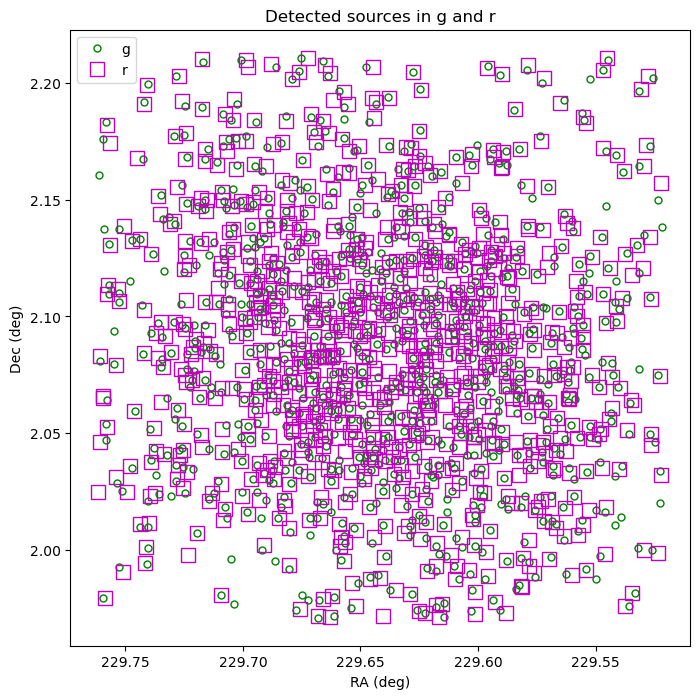

In [223]:
#************************* took this from labs
# make a plot of the RA and DEC of the sources in the g and r images

# boolean flags for good positions (> 20 pixels from every edge) in the g and r-band images
ny, nx = M5_data_g.shape
noedgeflag_g = ((sources_g['xcentroid'] > 20) & (sources_g['xcentroid'] < nx-20) &
                (sources_g['ycentroid'] > 20) & (sources_g['ycentroid'] < ny-20))
noedgeflag_r = ((sources_r['xcentroid'] > 20) & (sources_r['xcentroid'] < nx-20) &
                (sources_r['ycentroid'] > 20) & (sources_r['ycentroid'] < ny-20))

# open a figure
plt.figure(figsize=(8,8))

# plot the positions of the g sources
plt.plot(M5_ra_g[noedgeflag_g], M5_dec_g[noedgeflag_g],'g.',mfc='None',markersize=10,label='g')

# plot the positions of the r sources
plt.plot(M5_ra_r[noedgeflag_r], M5_dec_r[noedgeflag_r],'ms',mfc='None',markersize=10,label='r')

# add a legend
plt.legend()

# label your axes
plt.xlabel('RA (deg)')
plt.ylabel('Dec (deg)')
plt.gca().invert_xaxis()   # RA increases to the left on the sky
plt.title('Detected sources in g and r')

# save your plot
plt.savefig('M67_g_r_positions.png')

In [224]:
# this creates a SkyCoord object containing the g and r catalogs
g_catalog = SkyCoord(ra=M5_ra_g*u.degree, dec=M5_dec_g*u.degree)
r_catalog = SkyCoord(ra=M5_ra_r*u.degree, dec=M5_dec_r*u.degree)

# this matches the two catalogs and outputs an array of indices, idx, that when passed to r_catalog
# gives the ids of the matched sources for each source in g_catalog.
idx, d2d, d3d = g_catalog.match_to_catalog_sky(r_catalog)

# Consider regions the same source when they are within 0.0011111111 deg of each other (Found by sqrt((0.00111111111111)**2+(0)**2)
matchflag = d2d < 0.0011111111*u.deg
gmag = sources_g['mag'][matchflag]
rmag = sources_r['mag'][idx[matchflag]]

# also keep the sky position of each matched star (taken from the g catalog) for the radial analysis later
ra_match  = M5_ra_g[matchflag]
dec_match = M5_dec_g[matchflag]

print('number of matched stars:', matchflag.sum())
print(gmag, rmag)

number of matched stars: 400
    mag    
-----------
 0.19001153
 0.09491271
 -1.1086806
 0.34871745
 -1.4444427
 -1.0881927
 -1.4943177
  0.6411997
-0.92935395
 -2.3348444
        ...
 -1.6812174
  0.7327111
-0.87781596
 -1.0934017
 0.02709192
 0.87164944
  -2.045412
  1.2447475
 -2.1425266
   1.291928
Length = 400 rows     mag     
------------
 -0.47461456
   -0.254572
  -1.7859557
-0.034075394
  -1.8786356
  -1.8273562
  -1.5217823
  0.22706813
  -1.5178953
  -3.1196938
         ...
  -1.6835024
  0.18722968
  -0.5480872
  -1.5610094
 -0.04379243
-0.002770532
  -2.8387733
  0.94398713
  -2.2932122
  0.80204314
Length = 400 rows


In [226]:
# Calibration
# 22.5
gmag_cal = gmag + 22.5
rmag_cal = rmag + 22.5

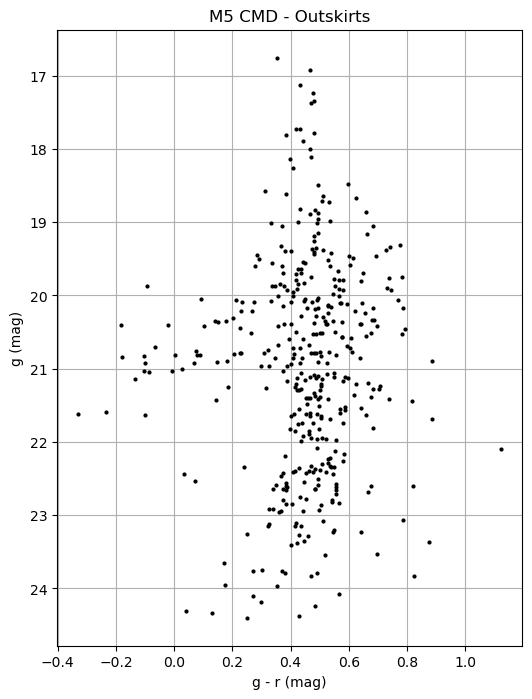

In [227]:
# CMD: g flux vs g - r color (lab used B-V)
plt.figure(figsize=(6,8))
plt.plot(gmag_cal - rmag_cal, gmag_cal, 'k.', markersize=4)
plt.xlabel('g - r (mag)')
plt.ylabel('g (mag)')
plt.title('M5 CMD - Outskirts')

plt.gca().invert_yaxis()   # brighter stars (smaller magnitudes) at the top
plt.grid(True)
plt.savefig('M5_CMD_all.png')

M5 has a suprisingly few number of red stars. Globular clusters tend to be older, so this few red stars is suprising. I expected to see a branch analogous to the red giant branch in the plot, but I do not. This likely has something to do with failing to include some stars. 